# BaTiO₃ nanoneedles: comparing batch-selection strategies for Bayesian optimization

**Goal.** Maximize the **aspect ratio** of BaTiO₃ nanoneedles (hydrothermal step) while keeping **phase purity** acceptable.
We have a small experimental dataset (Round 1) and want to propose the **next batch of q experiments** to run in parallel.
Choosing *one* next experiment is easy; choosing *q at once* is the hard part, so we compare several strategies **starting from the same data and the same GP model**:

| Prong | Strategy | Core idea |
|---|---|---|
| 1 (baseline) | Acquisition ranking + minimum-distance rule | Take the best-scoring candidates, but forbid near-duplicates |
| 2 (sequential) | Kriging believer, Constant liar (mean), Constant liar (low) | Pick one, *pretend* we know its result, update the GP, pick the next |
| 3 (joint) | q-EI and **q-NEI** (Monte-Carlo) | Score the *whole batch together* using the GP's joint (correlated) predictions |
| extra | Maximum-entropy sampling | Ignore the objective; pick the batch that is jointly most *informative* |

**How to read this notebook.** Every section matches a numbered step of the protocol text. Each code cell is preceded by a plain-language explanation of *what* we do and *why*. Run it top to bottom.

**Design decisions made in this notebook (you can change them in Step 1):**
* Optimization variables: `time_h`, `baoh_mass_g`, `water_initial_ml`.
* `hto_mass_g` is **not** used as a model input by default (explained below); a switch lets you include it.
* Aspect ratio is the only objective. Purity is an **acceptance criterion checked experimentally**, never predicted by the GP.
* Everything is implemented with `numpy`/`scipy` (no PyTorch/BoTorch needed). The GP is written out explicitly (about 40 lines) because we need to (i) model **oven-run (batch) effects** and (ii) condition it on fantasy points and draw joint samples. scikit-learn is used only to double-check our kernel.
* The GP includes a **batch random effect**: runs that went through the same oven run share an offset (Step 3 shows why this matters for your data).

## Step 1: Define the optimization problem

We must fix three things: **variables + ranges**, the **objective**, and the **feasibility rule**.

**Which inputs should the GP see? (HTO mass: yes or no?)**
My recommendation is **no, keep HTO out of the model** (`USE_HTO_IN_MODEL = False`), for these reasons:
1. In Round 1 HTO mass is essentially constant (≈0.140 g in 17 of 18 runs). A GP cannot learn the effect of a variable that was never varied.
2. The single exception (run 18, 0.1098 g) is also a replicate of a recipe whose twin gave a very different aspect ratio. With HTO as an input, the GP could "explain" that replicate-to-replicate scatter by HTO, which is a *confounded* conclusion from one point.
3. In the optimization HTO is fixed anyway, so a dimension we never move only adds model variance. With HTO fixed, the Ba(OH)₂ mass is a one-to-one proxy of the Ba:Ti ratio, so the chemistry is still covered.
4. Temperature (210 °C) and rinse water (10 mL) are also constant, so they are dropped for the same reason.

If we later *do* vary HTO deliberately, flip the switch. The notebook then adds it as an extra model input but still **never optimizes it** (candidates get a fixed HTO value).

In [ ]:
# ===================== USER CONFIGURATION (edit here) =====================
CSV_PATH   = "Experiment_Results_Rd1.csv"   # experimental dataset (one row per synthesis run)

# --- Variables we are allowed to change in the lab (the decision variables) ---
OPT_VARS = ["time_h", "baoh_mass_g", "water_initial_ml"]

# Scientifically/practically valid ranges [min, max]. Default = range already covered by Round 1.
# Widen them only if you trust the chemistry outside the explored region
# (the GP is far less reliable when extrapolating).
BOUNDS = {
    "time_h":           (1.0, 24.0),    # hours
    "baoh_mass_g":      (0.6, 2.0),   # g of Ba(OH)2
    "water_initial_ml": (25.0, 55.0),   # mL of water at the start of the reaction
}
# Resolution at which the lab can actually set each variable. The candidate pool is a grid with these steps,
# so every proposed recipe is something you can really weigh/pipette/program.
STEP = {"time_h": 1.0, "baoh_mass_g": 0.01, "water_initial_ml": 1.0}

# --- Should HTO mass be an (un-optimized) model input? See the discussion above. ---
USE_HTO_IN_MODEL = False

# --- Objective and feasibility ---
TARGET      = "aspect_ratio"   # quantity to MAXIMIZE
PURITY_COL  = "purity_pct"
PURITY_MIN  = 95.0             # acceptance threshold (% phase purity). Choose what is acceptable for you.

# --- Batch settings ---
Q    = 4      # batch size = number of experiments we can run together (e.g. autoclaves available)
SEED = 42     # reproducibility of everything random

# --- Acquisition function used by Prong 1 and Prong 2 (so both use the same scoring rule) ---
ACQ_NAME = "EI"   # "EI", "UCB" or "PI"
KAPPA    = 2.0    # exploration weight for UCB
XI       = 0.01   # small margin for EI / PI (in standardized units)

# --- Prong 1 parameter: minimum distance between chosen experiments ---
# Distances are Euclidean in the NORMALIZED space (each variable rescaled to [0, 1]).
# The diagonal of the cube is sqrt(3) ~ 1.73, so 0.25 means "at least ~15% of the diagonal apart".
D_MIN = 0.25

# --- Oven-run (batch) structure ---
# Runs made in the same oven run share an unknown offset (see Step 3). We need to know which oven run each row belongs to.
# If the CSV has a column called "batch_id" it is used; otherwise it is parsed from `notes` ("B3S2" -> oven run "B3").
# If a single oven run can only use ONE reaction time, restrict the candidate times here, e.g. ALLOWED_TIMES = [8.0]
# (then run the notebook once per time you are considering). None = any time in BOUNDS.
ALLOWED_TIMES = None

# --- GP prior bounds (standardized units: total variance of the target = 1) ---
# The data are too few to learn the surface freely, so we state weakly informative beliefs instead of letting the
# likelihood collapse to "no signal":
AMP2_BOUNDS = (0.10, 3.0)    # variance of the smooth recipe effect: at least 10% of the total variance
LS_BOUNDS   = (0.50, 5.0)    # lengthscales (unit cube): the response cannot change completely within <half of a variable's range
SB2_BOUNDS  = (1e-3, 3.0)    # variance of the oven-run (batch) offset
SN2_BOUNDS  = (1e-2, 2.0)    # run-to-run noise that remains after removing the batch offset

# --- Candidate pool hygiene ---
# Drop candidates closer than this (normalized distance) to an already-run recipe: no accidental repeats.
EXCLUDE_RADIUS = 0.05

# --- Monte-Carlo settings for the joint (q-EI / q-NEI) prong ---
N_MC_OPT   = 1024    # samples used *while optimizing* the batch
N_MC_EVAL  = 20000   # independent samples used to *score* every batch fairly in Step 10
SHORT_TOP, SHORT_RAND = 500, 1000   # shortlist for joint optimization: top-EI candidates + random candidates

# --- Lab constraints hook: return True for recipes you can actually run. Edit freely. ---
def lab_constraints(pool_df):
    """Example: keep everything. Replace with a real rule if needed, e.g. a maximum liner fill:
       return (pool_df['water_initial_ml'] + 3.0*pool_df['baoh_mass_g'] ) <= 60   # (made-up rule)"""
    return np.ones(len(pool_df), dtype=bool)

In [20]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.linalg import cho_factor, cho_solve, cholesky
from scipy.spatial.distance import cdist
from scipy.stats import norm
from scipy.optimize import minimize
from sklearn.gaussian_process.kernels import ConstantKernel, Matern   # only used to cross-check our own kernel
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RNG = np.random.default_rng(SEED)

## Step 2: Prepare and organize the experimental dataset

Each row is one synthesis run. Runs made with the **same recipe** are *replicates*: they are not independent pieces of information about the recipe space. We therefore give every recipe a `recipe_id` **computed from the synthesis parameters** (not copied from a label), so we can
* keep replicate information (and later cross-validate *by recipe*, never splitting replicates between train and test), and
* avoid treating replicates as different conditions.

Weighed masses never repeat exactly (0.7716 g vs 0.7717 g), so two runs are the same recipe if time, water, temperature match and the Ba(OH)₂ mass agrees within a small tolerance.

In [21]:
df_raw = pd.read_csv(CSV_PATH)
df_raw.columns = df_raw.columns.str.strip()          # protect against stray spaces in headers
df = df_raw.copy()

def assign_recipe_ids(d, baoh_tol=0.03):
    """Group runs into recipes: same temperature/time/water, and Ba(OH)2 mass within `baoh_tol` grams
    (single-linkage along sorted masses). Returns a copy with a `recipe_id` column."""
    d = d.copy()
    d["recipe_id"] = -1
    next_id = 1
    for _, sub in d.groupby(["temperature_c", "time_h", "water_initial_ml"], sort=False):
        sub = sub.sort_values("baoh_mass_g")
        new_cluster = (sub["baoh_mass_g"].diff().fillna(0) > baoh_tol).cumsum()   # start a new cluster after a big gap
        for _, idx in sub.groupby(new_cluster).groups.items():
            d.loc[idx, "recipe_id"] = next_id
            next_id += 1
    return d

df = assign_recipe_ids(df)

# ---- Cross-check against the `recipe_group` column that came with the CSV ----
if "recipe_group" in df.columns:
    check = df.groupby("recipe_id")["recipe_group"].nunique()
    bad = check[check > 1].index.tolist()
    if bad:
        print("WARNING: the CSV's `recipe_group` label disagrees with the actual parameters for these recipe_ids:", bad)
        print("The notebook uses the parameter-based `recipe_id`. Runs involved:")
        print(df[df.recipe_id.isin(bad)][["run_id","notes","time_h","baoh_mass_g","water_initial_ml","recipe_group","recipe_id"]]
              .sort_values(["recipe_id","run_id"]).to_string(index=False))
    else:
        print("recipe_group labels are consistent with the parameters.")
print(f"\n{len(df)} runs -> {df.recipe_id.nunique()} distinct recipes")

# ---- Oven-run (batch) id for every run ----
if "batch_id" in df.columns:
    df["batch_id"] = df["batch_id"].astype(str)
    print("Using the `batch_id` column of the CSV.")
else:
    parsed = df["notes"].astype(str).str.extract(r"^(B\d+)S\d+")[0]          # "B3S2" -> "B3"
    if parsed.notna().all():
        df["batch_id"] = parsed
        print("`batch_id` parsed from `notes` (pattern B<number>S<number>):", sorted(df.batch_id.unique()))
    else:
        df["batch_id"] = ["run" + str(r) for r in df["run_id"]]               # fallback: every run its own batch -> no batch effect
        print("WARNING: could not parse oven runs from `notes`; every run is treated as its own batch (no batch effect modelled).")

recipe_group labels are consistent with the parameters.

18 runs -> 9 distinct recipes
`batch_id` parsed from `notes` (pattern B<number>S<number>): ['B1', 'B2', 'B3', 'B4', 'B5', 'B6']


## Step 3: Preprocess and validate the data

Before modelling we check: missing values, units/ranges, constant columns, replicate scatter, outliers, and purity.
Two things matter a lot for a GP:
* **Constant columns** carry no information (and would break lengthscale fitting).
* **Replicate scatter** tells us how noisy the measurement + synthesis process is. If two replicates of the same recipe differ by a lot, the GP should *not* chase individual points. We let the GP learn a **noise level** (a `WhiteKernel`) from exactly this scatter.

In [22]:
# 1) Missing values in the columns we need
needed = OPT_VARS + [TARGET, PURITY_COL, "hto_mass_g", "temperature_c", "water_rinse_ml"]
print("Missing values per needed column:\n", df[needed].isna().sum().to_string(), "\n")

# 2) Constant columns (cannot be learned from)
for c in ["temperature_c", "water_rinse_ml", "hto_mass_g"]:
    print(f"{c:>16}: min={df[c].min():.4f}  max={df[c].max():.4f}  nunique={df[c].nunique()}")
assert df["temperature_c"].nunique() == 1 and df["water_rinse_ml"].nunique() == 1, \
    "Temperature or rinse water vary: add them to OPT_VARS/model inputs or handle them explicitly."

# 3) Are observed values inside the declared BOUNDS?
for v in OPT_VARS:
    lo_, hi_ = BOUNDS[v]
    tol = 0.5 * STEP[v]                      # weighed masses never hit the nominal value exactly
    inside = df[v].between(lo_ - tol, hi_ + tol).all()
    print(f"{v:>18}: data range [{df[v].min()}, {df[v].max()}]  bounds [{lo_}, {hi_}]  -> {'OK' if inside else 'DATA OUTSIDE BOUNDS'}")

# 4) HTO sanity check: flag runs whose HTO mass deviates >5% from the median
med = df["hto_mass_g"].median()
odd = df[(df["hto_mass_g"] / med - 1).abs() > 0.05]
if len(odd):
    print("\nHTO mass outlier(s), worth double-checking in the lab notebook (typo, or a real change of Ba:Ti ratio?):")
    print(odd[["run_id","notes","recipe_id","hto_mass_g","baoh_mass_g",TARGET]].to_string(index=False))

# 5) Purity = feasibility flag (NOT modelled)
df["feasible"] = df[PURITY_COL] >= PURITY_MIN
print(f"\nPurity >= {PURITY_MIN}% in {df.feasible.sum()} of {len(df)} runs (the GP never sees purity).")

# 6) Replicate scatter per recipe
rep = (df.groupby("recipe_id")
         .agg(n=(TARGET, "size"), time_h=("time_h", "first"), baoh_g=("baoh_mass_g", "mean"),
              water_ml=("water_initial_ml", "first"), AR_mean=(TARGET, "mean"),
              AR_min=(TARGET, "min"), AR_max=(TARGET, "max")))
rep["AR_range"] = rep["AR_max"] - rep["AR_min"]
print("\nReplicate scatter per recipe:")
print(rep.round(3).to_string())
print(f"\nMean replicate range = {rep.AR_range.mean():.2f} aspect-ratio units, "
      f"versus a spread of recipe means of {rep.AR_mean.max()-rep.AR_mean.min():.2f}.")
print("-> Replicate scatter is as large as the differences between recipes. Is it random, or does it have structure? See below.")

# 7) Is the replicate scatter *systematic by oven run*?  For recipes with replicates, take every run's deviation from its recipe
#    mean; if oven runs shift all their recipes up or down together, the batch means of these deviations are far from 0.
d_ = df.copy()
d_["dev"] = d_[TARGET] - d_.groupby("recipe_id")[TARGET].transform("mean")
d_ = d_[d_.groupby("recipe_id")[TARGET].transform("size") > 1]
bt = d_.groupby("batch_id").agg(time_h=("time_h", "first"), n_runs=("run_id", "size"), batch_offset=("dev", "mean"))
d_["resid"] = d_["dev"] - d_["batch_id"].map(bt["batch_offset"])
print("\nOven-run offsets (average deviation of the batch's runs from their recipe means):")
print(bt.round(2).to_string())
print(f"SD of batch offsets = {bt.batch_offset.std():.2f}   vs   SD of what is left after removing them = {d_.resid.std():.2f}")
print("-> If the first number is comparable to or larger than the second, a large part of the 'replicate noise' is a shared")
print("   oven-run effect (all recipes in the same oven run move together). That is NOT white noise, and the GP below models it explicitly.")

Missing values per needed column:
 time_h              0
baoh_mass_g         0
water_initial_ml    0
aspect_ratio        0
purity_pct          0
hto_mass_g          0
temperature_c       0
water_rinse_ml      0 

   temperature_c: min=210.0000  max=210.0000  nunique=1
  water_rinse_ml: min=10.0000  max=10.0000  nunique=1
      hto_mass_g: min=0.1098  max=0.1404  nunique=6
            time_h: data range [6, 24]  bounds [4.0, 24.0]  -> OK
       baoh_mass_g: data range [0.7712, 1.5434]  bounds [0.6, 2.0]  -> OK
  water_initial_ml: data range [30, 55]  bounds [25.0, 55.0]  -> OK

HTO mass outlier(s), worth double-checking in the lab notebook (typo, or a real change of Ba:Ti ratio?):
 run_id notes  recipe_id  hto_mass_g  baoh_mass_g  aspect_ratio
     18  B6S3          8      0.1098       0.7714     17.706665

Purity >= 95.0% in 18 of 18 runs (the GP never sees purity).

Replicate scatter per recipe:
           n  time_h  baoh_g  water_ml  AR_mean  AR_min  AR_max  AR_range
recipe_id       

## Step 4: Train the initial Gaussian-Process surrogate

**What a GP gives us.** For any candidate recipe **x** the GP returns a *prediction* **μ(x)** and an *uncertainty* **σ(x)**. It assumes "recipes that are close to each other give similar aspect ratios".

**Our model of one measurement:**

$$ y_{i} \;=\; f(\mathbf{x}_i) \;+\; b_{\text{oven run}(i)} \;+\; \varepsilon_i $$

* $f(\mathbf{x})$: the smooth **true recipe effect** we want to optimize. Kernel: Matérn-5/2 with one lengthscale per variable (ARD), amplitude `amp2`.
* $b$: an **oven-run offset** shared by all runs of the same oven run (variance `sb2`).
* $\varepsilon$: the **leftover noise** (variance `sn2`).

Why the extra $b$ term? Without it, the oven-run effect has to be explained either as a "recipe effect" (the GP would chase it) or as white noise (the GP would give up). Modelling it separately lets the GP see $f$ through it. Note that the optimizer only ever cares about $f$, never about $b$: a *new* oven run gets a new, unknown offset.

**Preprocessing.** Inputs are rescaled to the unit cube [0, 1] (so hours, grams and mL are comparable). The target is standardized (mean 0, std 1); acquisition values below are in these standardized units and are converted back to real aspect-ratio units only for reporting.

**Fitting.** The three variances and the lengthscales are found by maximizing the **marginal likelihood** (how probable the data are under the model), with the prior bounds from Step 1.

In [23]:
# ---------- scaling helpers ----------
lo = np.array([BOUNDS[v][0] for v in OPT_VARS]); hi = np.array([BOUNDS[v][1] for v in OPT_VARS])
N_OPT = len(OPT_VARS)                       # the first N_OPT model columns are always the optimization variables

if USE_HTO_IN_MODEL:
    HTO_LO, HTO_HI = df["hto_mass_g"].min(), df["hto_mass_g"].max()
    HTO_FIXED = float(df["hto_mass_g"].median())      # value assigned to every *candidate* (HTO is never optimized)

def to_model(raw_opt):
    """raw (hours, g, mL) matrix -> model input matrix in [0,1] (+ constant HTO column if enabled)."""
    U = (np.atleast_2d(raw_opt) - lo) / (hi - lo)
    if USE_HTO_IN_MODEL:
        U = np.column_stack([U, np.full(len(U), (HTO_FIXED - HTO_LO) / (HTO_HI - HTO_LO))])
    return U

# ---------- training data (one row per run) ----------
U_obs = (df[OPT_VARS].values - lo) / (hi - lo)
X_obs = np.column_stack([U_obs, (df["hto_mass_g"].values - HTO_LO) / (HTO_HI - HTO_LO)]) if USE_HTO_IN_MODEL else U_obs
y_raw = df[TARGET].values.astype(float)
Y_MEAN, Y_SD = y_raw.mean(), y_raw.std(ddof=0)
y_obs = (y_raw - Y_MEAN) / Y_SD              # standardized target
feas_obs = df["feasible"].values             # purity-based feasibility mask of observed runs
groups_obs = df["recipe_id"].values          # which recipe each run belongs to
batch_obs = pd.factorize(df["batch_id"])[0]  # which oven run each run belongs to (integer code)

# ---------- recipe-level view (one row per distinct recipe): used for the "incumbent" ----------
rec_ids = np.unique(groups_obs)
X_rec = np.array([X_obs[groups_obs == g].mean(axis=0) for g in rec_ids])
feas_rec = np.array([feas_obs[groups_obs == g].all() for g in rec_ids])   # recipe accepted only if all its runs are pure enough

# ---------- the GP, written out ----------
def matern52(A, B, ls, amp2):
    """Matern-5/2 kernel with one lengthscale per input (ARD):  amp2 * (1 + sqrt5 r + 5 r^2 / 3) * exp(-sqrt5 r),
    where r is the Euclidean distance after dividing each coordinate by its lengthscale."""
    r = np.sqrt((((A[:, None, :] - B[None, :, :]) / ls) ** 2).sum(-1))
    s = np.sqrt(5.0) * r
    return amp2 * (1.0 + s + s ** 2 / 3.0) * np.exp(-s)

def train_cov(H, X, batch):
    """Covariance of the measured values: smooth recipe effect + shared oven-run offset + independent noise."""
    same_oven = (batch[:, None] == batch[None, :]).astype(float)
    return matern52(X, X, H["ls"], H["amp2"]) + H["sb2"] * same_oven + (H["sn2"] + 1e-8) * np.eye(len(X))

def unpack(theta, d, null=False):
    """theta = log of [amp2, ls_1..ls_d, sb2, sn2]. null=True switches the smooth recipe effect OFF (amp2 ~ 0)."""
    return {"amp2": 1e-8 if null else float(np.exp(theta[0])), "ls": np.exp(theta[1:1 + d]),
            "sb2": float(np.exp(theta[1 + d])), "sn2": float(np.exp(theta[2 + d]))}

def neg_log_marginal_likelihood(theta, X, y, batch, null=False):
    H = unpack(theta, X.shape[1], null)
    try:
        L = cholesky(train_cov(H, X, batch), lower=True)
    except Exception:
        return 1e10                                           # not positive definite -> reject this hyperparameter set
    a = cho_solve((L, True), y)
    return 0.5 * y @ a + np.log(np.diag(L)).sum() + 0.5 * len(y) * np.log(2 * np.pi)

def fit_gp(X, y, batch, n_restarts=40, null=False, seed=SEED):
    """Maximize the marginal likelihood from many random starts (the surface has several local optima)."""
    d = X.shape[1]
    bnds = ([tuple(np.log(AMP2_BOUNDS))] + [tuple(np.log(LS_BOUNDS))] * d
            + [tuple(np.log(SB2_BOUNDS)), tuple(np.log(SN2_BOUNDS))])
    r = np.random.default_rng(seed)
    best = None
    for _ in range(n_restarts):
        res = minimize(neg_log_marginal_likelihood, [r.uniform(a, b) for a, b in bnds], args=(X, y, batch, null),
                       method="L-BFGS-B", bounds=bnds)
        if best is None or res.fun < best.fun: best = res
    H = unpack(best.x, d, null); H["nll"] = float(best.fun)
    return H

def posterior(H, X, y, batch, Xs, full_cov=False):
    """Posterior of the LATENT function f at points Xs (no oven offset, no noise):
         mean = K*  (K + offsets + noise)^-1 y
         cov  = K** - K*  (K + offsets + noise)^-1  K*^T
    full_cov=False returns only variances (cheap for the 38k-candidate pool)."""
    cf = cho_factor(train_cov(H, X, batch), lower=True)
    Ks = matern52(Xs, X, H["ls"], H["amp2"])
    mu = Ks @ cho_solve(cf, y)
    V = cho_solve(cf, Ks.T)
    if full_cov:
        return mu, matern52(Xs, Xs, H["ls"], H["amp2"]) - Ks @ V
    return mu, np.maximum(H["amp2"] - np.einsum("ij,ji->i", Ks, V), 1e-12)

H = fit_gp(X_obs, y_obs, batch_obs)

def predict(Xs, X=None, y=None, batch=None, full_cov=False):
    """Posterior with the FITTED hyperparameters. By default conditioned on the real data; pass (X, y, batch) to
    condition on real data + fantasy points instead (Prong 2)."""
    return posterior(H, X_obs if X is None else X, y_obs if y is None else y,
                     batch_obs if batch is None else batch, Xs, full_cov)

# ---------- sanity check of our kernel against scikit-learn's ----------
A_, B_ = np.random.default_rng(0).random((6, X_obs.shape[1])), np.random.default_rng(1).random((5, X_obs.shape[1]))
sk = ConstantKernel(H["amp2"], "fixed") * Matern(length_scale=H["ls"], nu=2.5, length_scale_bounds="fixed")
print("max |our kernel - sklearn kernel| =", np.abs(matern52(A_, B_, H["ls"], H["amp2"]) - sk(A_, B_)).max().round(10), "(should be ~0)")

# ---------- what did the fit say? ----------
tot = H["amp2"] + H["sb2"] + H["sn2"]
print("\nVariance decomposition (share of total):")
print(f"  smooth recipe effect f : {100*H['amp2']/tot:5.1f}%   (amp2 = {H['amp2']:.2f})")
print(f"  oven-run offset b      : {100*H['sb2']/tot:5.1f}%   (sb2  = {H['sb2']:.2f})")
print(f"  leftover noise         : {100*H['sn2']/tot:5.1f}%   (sn2  = {H['sn2']:.2f})")
names_model = OPT_VARS + (["hto"] if USE_HTO_IN_MODEL else [])
print("Lengthscales (unit cube; long = that variable barely matters):", {n: round(float(v), 2) for n, v in zip(names_model, H["ls"])})
for n, v in zip(names_model, H["ls"]):
    if v >= LS_BOUNDS[1] * 0.99: print(f"  note: '{n}' is at the upper lengthscale bound -> the data see no effect of this variable")
if H["amp2"] <= AMP2_BOUNDS[0] * 1.01:
    print("  note: the recipe-effect amplitude sits on its LOWER bound -> see the evidence test below.")

max |our kernel - sklearn kernel| = 0.0 (should be ~0)

Variance decomposition (share of total):
  smooth recipe effect f :   8.6%   (amp2 = 0.10)
  oven-run offset b      :  71.6%   (sb2  = 0.83)
  leftover noise         :  19.7%   (sn2  = 0.23)
Lengthscales (unit cube; long = that variable barely matters): {'time_h': 0.5, 'baoh_mass_g': 5.0, 'water_initial_ml': 5.0}
  note: 'baoh_mass_g' is at the upper lengthscale bound -> the data see no effect of this variable
  note: 'water_initial_ml' is at the upper lengthscale bound -> the data see no effect of this variable
  note: the recipe-effect amplitude sits on its LOWER bound -> see the evidence test below.


**Is there any evidence of a recipe effect at all?** Compare the fitted model with a **null model** in which the smooth recipe effect $f$ is switched off (only oven-run offsets + noise). The gain in log-likelihood is the evidence for $f$ in the data. Roughly: a gain below ~2 nats means "the data cannot tell the difference".

This matters because a GP will happily return *some* surface; the question is whether the data support it. If there is no evidence, the proposals of every strategy are driven mostly by the **prior** (and by where the data are missing), i.e. they are exploration, and the *design of the experiments* (how runs are spread over oven runs) is what will make the next round informative.

In [41]:
H_null = fit_gp(X_obs, y_obs, batch_obs, null=True)
gain = H_null["nll"] - H["nll"]
print(f"log-likelihood gain from including a smooth recipe effect: {gain:.2f} nats")
if gain < 2:
    print("-> Weak/no evidence for a recipe effect in this dataset once oven-run offsets are accounted for.")
    print("   The surrogate surface below is therefore mostly prior; treat the batches as exploration and do not over-read the predictions.")
else:
    print("-> The data support a smooth recipe effect.")

log-likelihood gain from including a smooth recipe effect: -0.27 nats
-> Weak/no evidence for a recipe effect in this dataset once oven-run offsets are accounted for.
   The surrogate surface below is therefore mostly prior; treat the batches as exploration and do not over-read the predictions.


**Leave-one-recipe-out cross-validation.** We hide *both replicates* of one recipe, refit the GP on the rest, predict the hidden recipe, and repeat for all recipes. Splitting by recipe (not by row) is essential: if one replicate stayed in training the model would "cheat". The baseline is "always predict the training mean". The target here is the raw measurement (which still contains the unpredictable oven offset), so RMSE values stay high even for a good model.

In [25]:
def loo_recipe_cv(X, y, batch, groups, n_restarts=10):
    pred, base = np.zeros_like(y), np.zeros_like(y)
    for g in np.unique(groups):
        te = groups == g
        Hg = fit_gp(X[~te], y[~te], batch[~te], n_restarts=n_restarts)
        pred[te], _ = posterior(Hg, X[~te], y[~te], batch[~te], X[te])
        base[te] = y[~te].mean()
    return pred, base

pred_cv, base_cv = loo_recipe_cv(X_obs, y_obs, batch_obs, groups_obs)
rmse_gp   = np.sqrt(np.mean((pred_cv - y_obs) ** 2)) * Y_SD
rmse_base = np.sqrt(np.mean((base_cv - y_obs) ** 2)) * Y_SD
print(f"Leave-one-recipe-out RMSE: GP = {rmse_gp:.2f}   |  'predict the mean' baseline = {rmse_base:.2f}   (aspect-ratio units)")
print("GP clearly better than the baseline." if rmse_gp < 0.9 * rmse_base else
      "GP is not clearly better than the baseline: the data are too noisy/sparse to learn the response surface yet. "
      "Batch strategies still produce proposals, but treat them as exploration.")

Leave-one-recipe-out RMSE: GP = 3.00   |  'predict the mean' baseline = 3.05   (aspect-ratio units)
GP is not clearly better than the baseline: the data are too noisy/sparse to learn the response surface yet. Batch strategies still produce proposals, but treat them as exploration.


**What did the GP learn?** Predicted aspect ratio (colors) over time × Ba(OH)₂ mass at three initial-water volumes (low / middle / high). Dots are the observed runs with water within ±6 mL of the slice.

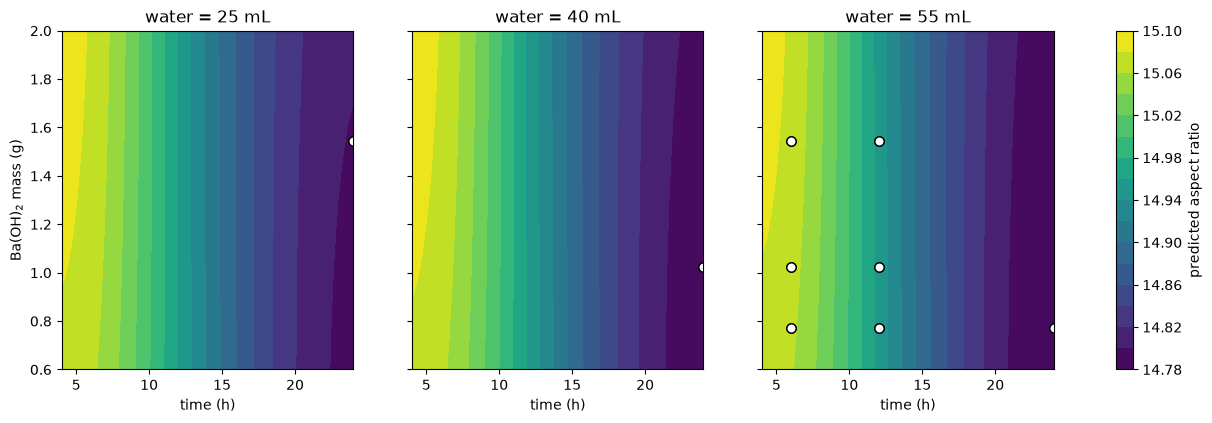

Predicted aspect ratio spans only 0.30 units across this slice: compare with the replicate scatter in Step 3. A nearly flat surface = the model has found little structure to exploit.


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
gt, gb = np.linspace(lo[0], hi[0], 60), np.linspace(lo[1], hi[1], 60)
Tm, Bm = np.meshgrid(gt, gb)
for ax, w in zip(axes, np.linspace(lo[2], hi[2], 3)):
    raw = np.column_stack([Tm.ravel(), Bm.ravel(), np.full(Tm.size, w)])
    mu_s, _ = predict(to_model(raw))
    cs = ax.contourf(Tm, Bm, (mu_s * Y_SD + Y_MEAN).reshape(Tm.shape), levels=15, cmap="viridis")
    near = (df["water_initial_ml"] - w).abs() <= 6
    ax.scatter(df.loc[near, "time_h"], df.loc[near, "baoh_mass_g"], c="white", edgecolor="k", s=45)
    ax.set_title(f"water = {w:.0f} mL"); ax.set_xlabel("time (h)")
axes[0].set_ylabel("Ba(OH)$_2$ mass (g)")
fig.colorbar(cs, ax=axes, label="predicted aspect ratio"); plt.show()
mu_all, _ = predict(to_model(np.column_stack([np.repeat(gt, 5), np.tile(np.linspace(lo[1], hi[1], 5), len(gt)), np.full(len(gt) * 5, lo[2] + 0.5 * (hi[2] - lo[2]))])))
print(f"Predicted aspect ratio spans only {np.ptp(mu_all) * Y_SD:.2f} units across this slice: compare with the replicate scatter in Step 3. "
      "A nearly flat surface = the model has found little structure to exploit.")

## Step 5: Common candidate pool

All strategies must choose from the **same list of possible experiments**, otherwise differences in the results could come from the list, not from the strategy. We build a regular grid over the bounds (using the lab-realistic STEP sizes), apply the lab constraints, and drop candidates that are essentially repeats of recipes already run.

The same `gp` (fitted above) is the common starting model for every strategy.

In [27]:
axes_vals = [np.round(np.arange(BOUNDS[v][0], BOUNDS[v][1] + STEP[v] / 2, STEP[v]), 4) for v in OPT_VARS]
grid = np.meshgrid(*axes_vals, indexing="ij")
pool_raw = np.column_stack([g.ravel() for g in grid])               # every combination of the three variables
pool_df = pd.DataFrame(pool_raw, columns=OPT_VARS)

keep = np.asarray(lab_constraints(pool_df), dtype=bool)             # practical lab constraints
if ALLOWED_TIMES is not None:                                       # e.g. a single oven run can only use one time
    keep &= pool_df["time_h"].isin(ALLOWED_TIMES).values
d_to_obs = cdist((pool_raw - lo) / (hi - lo), U_obs).min(axis=1)    # distance to the closest already-run experiment
keep &= d_to_obs >= EXCLUDE_RADIUS

pool_raw = pool_raw[keep]; pool_df = pool_df[keep].reset_index(drop=True)
U_pool = (pool_raw - lo) / (hi - lo)       # unit-cube coordinates of the optimization variables (used for distances)
X_pool = to_model(pool_raw)                # model inputs (same as U_pool unless HTO is included)
print(f"Candidate pool: {len(pool_df):,} recipes "
      f"({' x '.join(str(len(a)) for a in axes_vals)} grid, minus lab constraints and repeats of tested recipes)")

Candidate pool: 91,500 recipes (21 x 141 x 31 grid, minus lab constraints and repeats of tested recipes)


### Shared tools: acquisition functions and the "incumbent"

An **acquisition function** turns (μ, σ) into one number that says *how attractive is it to run this experiment*:
* **UCB** = μ + κσ: optimism in the face of uncertainty.
* **EI** (expected improvement) = expected amount by which the experiment beats the current best.
* **PI** = probability of beating the current best (ignores *by how much*).

**The incumbent (`BEST_F`).** EI/PI need "the current best". Our measurements are noisy (replicates differ by several units!), so the *largest raw measurement* is biased upward by luck. A more honest incumbent is the **largest posterior mean among the observed (purity-acceptable) recipes**. We use that and keep it fixed for all strategies so the comparison is fair.

All acquisition values use σ of the **latent function** (what the recipe truly yields on average), not the noisy predictive σ.

In [ ]:
def acq_ucb(mu, sd, best_f): return mu + KAPPA * sd
def acq_ei(mu, sd, best_f):
    z = (mu - best_f - XI) / sd
    return (mu - best_f - XI) * norm.cdf(z) + sd * norm.pdf(z)
def acq_pi(mu, sd, best_f): return norm.cdf((mu - best_f - XI) / sd)
ACQS = {"UCB": acq_ucb, "EI": acq_ei, "PI": acq_pi}
ACQ = ACQS["EI"]

mu_at_rec, _ = predict(X_rec)
BEST_F    = mu_at_rec[feas_rec].max()     # robust incumbent: best posterior mean of f among accepted recipes (free of oven offsets)
Y_OBS_MAX = y_obs[feas_obs].max()         # classical incumbent (largest raw measurement, oven offset included), only used by plain q-EI

# GP predictions over the whole pool (real data only): used by Prong 1 and by the reporting tables
mu_pool, var_pool = predict(X_pool)
sd_pool = np.sqrt(var_pool)
print(f"Incumbent (standardized) = {BEST_F:.3f}  ->  {BEST_F*Y_SD+Y_MEAN:.2f} aspect-ratio units "
      f"(largest raw measurement: {y_raw[feas_obs].max():.2f})")

Incumbent (standardized) = 0.048  ->  15.07 aspect-ratio units (largest raw measurement: 21.82)


## Step 6 (Prong 1): acquisition ranking + minimum-distance selection

**Naive idea:** score every candidate with the acquisition function and take the top q. **Problem:** the top scores usually sit next to each other (they are all near the same promising spot), so we would run q nearly identical experiments and learn almost nothing extra.

**Fix:** walk down the ranked list, and accept a candidate only if it is at least `D_MIN` (normalized distance) away from every candidate already accepted. This is cheap and robust, but it is *geometric*: it does not know how the *outcomes* of nearby experiments are correlated.

In [29]:
def min_distance_batch(scores, U, q, d_min):
    """Greedy: go through candidates by decreasing score; keep one only if >= d_min from all kept ones."""
    chosen = []
    for j in np.argsort(-scores):
        if all(np.linalg.norm(U[j] - U[k]) >= d_min for k in chosen):
            chosen.append(j)
            if len(chosen) == q: break
    if len(chosen) < q:
        print(f"WARNING: only {len(chosen)} candidates satisfy D_MIN={d_min}; lower D_MIN or widen the bounds.")
    return np.array(chosen)

scores_p1 = ACQ(mu_pool, sd_pool, BEST_F)
batch_p1 = min_distance_batch(scores_p1, U_pool, Q, D_MIN)
print(f"Prong 1 ({ACQ_NAME} + min distance {D_MIN}) picked pool rows: {batch_p1}")

Prong 1 (EI + min distance 0.25) picked pool rows: [4340 4348 4356 3255]


## Step 7 (Prong 2): sequential selection with fantasy observations

**Idea.** Pick the best candidate with the acquisition function. We cannot run it yet, but we can **pretend** we did and got a made-up result (a *fantasy*). Add that fantasy to a *temporary copy* of the data, update the GP (same hyperparameters, new conditioning), recompute the acquisition and pick the next candidate. Repeat until q are chosen. The made-up point shrinks the GP's uncertainty (and sometimes the mean) around the chosen recipe, so the next pick is pushed elsewhere.

Three ways to invent the result:
* **Kriging believer (KB):** use the GP's own prediction μ(x). Neutral: it changes the *uncertainty* only, not the mean.
* **Constant liar, mean (CL-mean):** every chosen point is "observed" at the average observed value. Mildly pessimistic near good regions.
* **Constant liar, low (CL-low):** every chosen point is "observed" at the *worst* observed value. Strongly discourages neighbours, i.e. the most exploratory/spread-out variant.

**Important:** fantasies live only inside this function. `X_obs`/`y_obs` are never modified, and fantasies are never written to any dataset.

In [30]:
def sequential_batch(strategy, q):
    """strategy in {'KB','CL_mean','CL_low'}; returns the chosen pool rows in selection order."""
    n_real = len(X_obs)
    X_aug, y_aug, b_aug = X_obs.copy(), y_obs.copy(), batch_obs.copy()   # TEMPORARY copies: real data stay untouched
    chosen = []
    for _ in range(q):
        mu, var = predict(X_pool, X_aug, y_aug, b_aug) # GP conditioned on real + fantasy points
        score = ACQ(mu, np.sqrt(var), BEST_F)          # same acquisition (and incumbent) as Prong 1
        score[chosen] = -np.inf                        # never pick the same candidate twice
        j = int(np.argmax(score)); chosen.append(j)
        # --- invent the fantasy outcome (standardized units) ---
        if   strategy == "KB":      lie = mu[j]
        elif strategy == "CL_mean": lie = y_obs.mean()
        elif strategy == "CL_low":  lie = y_obs.min()
        else: raise ValueError(strategy)
        X_aug = np.vstack([X_aug, X_pool[j]]); y_aug = np.append(y_aug, lie)
        b_aug = np.append(b_aug, b_aug.max() + 1)       # the fantasy gets an oven run of its own (no shared offset)
    assert len(X_obs) == n_real and len(y_obs) == n_real   # fantasies were never added to the real data
    return np.array(chosen)

batch_kb  = sequential_batch("KB", Q)
batch_clm = sequential_batch("CL_mean", Q)
batch_cll = sequential_batch("CL_low", Q)
print("Kriging believer :", batch_kb)
print("Constant liar mean:", batch_clm)
print("Constant liar low :", batch_cll)

Kriging believer : [4340 4309 4341 4370]
Constant liar mean: [4340 4309 4370 4278]
Constant liar low : [ 4340 91469    30 47894]


## Step 8 (Prong 3): joint batch BO with q-EI and q-NEI

**Joint view.** Prong 1 scores candidates one by one; Prong 2 scores them one after another with pretend data. Prong 3 evaluates a **whole batch as one object**.

**q-EI via Monte Carlo (the "sampling" idea).**
1. Draw many plausible versions of the true response surface from the GP's **joint** posterior over the batch (this keeps the correlations: if two recipes are close, they go up or down *together* in each sample).
2. In each sample, the batch's result is the **best** of its q recipes. The improvement is `max(0, best of batch − incumbent)`.
3. Average over samples: that is q-EI.

Two nearby recipes are highly correlated, so they rarely beat each other by much: adding the second contributes little, and the criterion automatically prefers a spread-out batch, with no distance threshold needed.

**q-NEI (noisy EI).** Our incumbent is itself uncertain (noisy measurements). q-NEI draws the incumbent **inside each sample too**: it uses the best *sampled* value of $f$ among the already-tested recipes, instead of one fixed number. (Plain q-EI below uses the largest raw measurement, which still contains the lucky oven offset, so expect it to be hard to beat.) This is the version I recommend with replicate scatter this large. (BoTorch's `qLogNoisyExpectedImprovement` is the numerically stabilized form of the same idea; it is not needed at this tiny scale.)

**Optimizing over batches.** Searching all combinations of q out of ~38,000 candidates is impossible, so we use **sequential greedy** maximization (as BoTorch does): add the candidate that most increases the *joint* value, given those already in the batch. Unlike Prong 2, the earlier picks are **not** treated as fantasies with fixed values: each Monte-Carlo sample carries the uncertainty. To keep it fast we search a **shortlist** (top-EI candidates + random ones) and reuse the same random numbers for every evaluation (common random numbers) so comparisons are stable.

In [31]:
def safe_cholesky(cov, base_jitter=1e-6):
    """Cholesky of a covariance that may be numerically singular (near-duplicate points): add growing jitter."""
    jit = base_jitter * np.mean(np.diag(cov))
    for _ in range(8):
        try:
            return cholesky(cov + jit * np.eye(len(cov)), lower=True)
        except Exception:
            jit *= 10
    raise np.linalg.LinAlgError("covariance not positive definite even with jitter")

def joint_samples(X_extra, n_samples, seed):
    """Joint posterior samples of the latent function f at [observed recipes ; X_extra]. Shape (n_rec+len(X_extra), S)."""
    Xj = np.vstack([X_rec, X_extra])
    mu, cov = predict(Xj, full_cov=True)
    L = safe_cholesky(cov)
    Z = np.random.default_rng(seed).standard_normal((len(Xj), n_samples))
    return mu[:, None] + L @ Z

def incumbent_samples(F, noisy):
    """Incumbent per Monte-Carlo sample. noisy=True (q-NEI): best sampled value among accepted observed recipes.
       noisy=False (plain q-EI): one fixed number = best raw measurement."""
    n = len(X_rec)
    return F[:n][feas_rec].max(axis=0) if noisy else np.full(F.shape[1], Y_OBS_MAX)

def greedy_joint_batch(q, noisy, n_samples=N_MC_OPT, seed=SEED):
    # ---- shortlist: promising (top EI) + random (so the batch can also pick exploratory spots) ----
    ei = acq_ei(mu_pool, sd_pool, BEST_F)
    top = np.argsort(-ei)[:SHORT_TOP]
    rest = np.setdiff1d(np.arange(len(X_pool)), top)
    rnd = np.random.default_rng(seed).choice(rest, size=min(SHORT_RAND, len(rest)), replace=False)
    short = np.concatenate([top, rnd])
    # ---- ONE set of joint samples for the whole shortlist (common random numbers) ----
    F = joint_samples(X_pool[short], n_samples, seed)
    inc = incumbent_samples(F, noisy)
    Fc = F[len(X_rec):]                                   # (M, S) sampled values of every shortlisted candidate
    best_in_batch = np.full(n_samples, -np.inf)
    chosen = []
    for _ in range(q):
        cur = np.maximum(best_in_batch[None, :], Fc)      # batch best if we add candidate m (M, S)
        gain = np.maximum(cur - inc[None, :], 0).mean(axis=1)   # Monte-Carlo (q)EI of "batch so far + m"
        gain[chosen] = -np.inf
        m = int(np.argmax(gain)); chosen.append(m)
        best_in_batch = cur[m]
    return short[np.array(chosen)]

batch_qei  = greedy_joint_batch(Q, noisy=False)
batch_qnei = greedy_joint_batch(Q, noisy=True)
print("q-EI  (fixed incumbent)   :", batch_qei)
print("q-NEI (noisy incumbent)   :", batch_qnei)

q-EI  (fixed incumbent)   : [4340 4309 4341 4278]
q-NEI (noisy incumbent)   : [ 4340 65162   712 22083]


## Step 9 (optional benchmark): maximum-entropy batch selection

**Idea.** Ignore the objective completely. Choose the batch whose predicted outcomes are *jointly* the most uncertain, i.e. that maximizes the Gaussian entropy

$$H(X_B)=\tfrac12\log\!\big((2\pi e)^q\,\det K_B\big),$$

where $K_B$ is the GP predictive covariance of the batch (we add the leftover-noise variance on the diagonal because we will observe noisy measurements). Maximizing $\det K_B$ favours recipes that are individually uncertain **and** mutually uncorrelated (far apart): the batch teaches us the most about the whole response surface.

**Practical trick.** A GP's variance does not depend on the observed values, only on *where* we measured. The greedy log-det maximizer is therefore: pick the point with the largest variance, add it as a (dummy) data point, recompute variances, repeat.

**Expect:** points pushed toward the *corners/edges* of the box (that is where the GP knows least). It is an information-seeking benchmark, not a way to find a high aspect ratio.

In [32]:
def max_entropy_batch(q):
    X_aug, y_aug, b_aug = X_obs.copy(), y_obs.copy(), batch_obs.copy()
    chosen = []
    for _ in range(q):
        _, var = predict(X_pool, X_aug, y_aug, b_aug)  # variance only depends on locations, so the dummy y below is irrelevant
        var[chosen] = -np.inf
        j = int(np.argmax(var)); chosen.append(j)
        X_aug = np.vstack([X_aug, X_pool[j]]); y_aug = np.append(y_aug, 0.0); b_aug = np.append(b_aug, b_aug.max() + 1)
    return np.array(chosen)

batch_ent = max_entropy_batch(Q)
print("Max-entropy:", batch_ent)

Max-entropy: [91499  4340 65347     0]


## Step 10: Compare the proposed batches

Every batch is now scored with the **same yardsticks** (so no strategy is judged by its own criterion alone):

| Metric | Meaning | Higher is… |
|---|---|---|
| `qNEI` / `qEI` | Expected improvement of the whole batch over the incumbent, in aspect-ratio units (independent Monte-Carlo samples, not the ones used for optimizing) | better for finding high aspect ratio |
| `logdet` | Joint entropy criterion (up to constants) | more informative |
| `min_dist`, `mean_dist` | Normalized spread between the batch's recipes | more diverse |
| `fill` | Average distance from random recipes to the nearest tested-or-proposed recipe | **lower** = better coverage of the space |
| `mean_mu`, `mean_sd` | Average predicted aspect ratio / uncertainty of the batch | exploitation vs exploration |

**Remember: purity is not predicted.** A recipe with a high predicted aspect ratio is only a *candidate*; purity must still be measured (XRD).

In [33]:
BATCHES = {
    f"P1 {ACQ_NAME}+min-dist":  batch_p1,
    "P2 Kriging believer":      batch_kb,
    "P2 Constant liar (mean)":  batch_clm,
    "P2 Constant liar (low)":   batch_cll,
    "P3 q-EI":                  batch_qei,
    "P3 q-NEI":                 batch_qnei,
    "Entropy (max-entropy)":    batch_ent,
}

def mc_q_improvement(idx, noisy, n_samples=N_MC_EVAL, seed=12345):
    """Independent Monte-Carlo estimate of qEI/qNEI for the batch pool[idx], in aspect-ratio units."""
    F = joint_samples(X_pool[idx], n_samples, seed)
    inc = incumbent_samples(F, noisy)
    return np.maximum(F[len(X_rec):].max(axis=0) - inc, 0).mean() * Y_SD

def batch_logdet(idx):
    """Joint entropy H(X_B) in nats, with noise added to the predictive covariance."""
    _, cov = predict(X_pool[idx], full_cov=True)
    K_B = cov + H["sn2"] * np.eye(len(idx))
    return 0.5 * (len(idx) * np.log(2 * np.pi * np.e) + np.linalg.slogdet(K_B)[1])

# random probe points for the "fill" (coverage) metric
probe = RNG.random((4000, N_OPT))
def fill_distance(idx):
    reference = np.vstack([U_obs, U_pool[idx]])
    return cdist(probe, reference).min(axis=1).mean()

rows = []
for name, idx in BATCHES.items():
    dd = [np.linalg.norm(U_pool[a] - U_pool[b]) for a, b in combinations(idx, 2)]
    rows.append({"strategy": name,
                 "qNEI": mc_q_improvement(idx, True), "qEI": mc_q_improvement(idx, False),
                 "logdet": batch_logdet(idx),
                 "min_dist": min(dd), "mean_dist": np.mean(dd), "fill": fill_distance(idx),
                 "mean_mu": (mu_pool[idx] * Y_SD + Y_MEAN).mean(), "mean_sd": (sd_pool[idx] * Y_SD).mean()})
summary = pd.DataFrame(rows).set_index("strategy")
print(f"Reference: fill distance of the existing data alone = "
      f"{cdist(probe, U_obs).min(axis=1).mean():.3f}\n")
display(summary.round(3))

Reference: fill distance of the existing data alone = 0.381



,qNEI,qEI,logdet,min_dist,mean_dist,fill,mean_mu,mean_sd
strategy,,,,,,,,
P1 EI+min-dist,0.080,0.0,3.158,0.250,0.379,0.335,15.089,0.844
P2 Kriging believer,0.087,0.0,3.163,0.007,0.507,0.355,15.089,0.845
P2 Constant liar (mean),0.087,0.0,3.163,0.007,0.505,0.356,15.089,0.845
P2 Constant liar (low),0.128,0.0,3.270,1.000,1.254,0.327,14.966,0.842
P3 q-EI,0.069,0.0,3.158,0.007,0.022,0.356,15.090,0.846
P3 q-NEI,0.134,0.0,3.238,0.702,1.067,0.310,15.009,0.835
Entropy (max-entropy),0.133,0.0,3.268,0.700,1.185,0.322,14.951,0.846


**The experiments themselves.** For each strategy: the proposed recipes with the GP's prediction (real aspect-ratio units) and the *single-experiment* EI of each (note how a recipe can have a modest individual EI yet belong to a good *batch*).

In [34]:
recs = []
for name, idx in BATCHES.items():
    for rank, j in enumerate(idx, 1):
        recs.append({"strategy": name, "pick": rank,
                     **{v: pool_raw[j, i] for i, v in enumerate(OPT_VARS)},
                     "pred_AR": mu_pool[j] * Y_SD + Y_MEAN, "sd_AR": sd_pool[j] * Y_SD,
                     "EI_single": acq_ei(mu_pool[j:j+1], sd_pool[j:j+1], BEST_F)[0] * Y_SD, "pool_row": j})
proposals = pd.DataFrame(recs)
display(proposals.round(3))

# How much do the strategies agree? (number of identical recipes shared by two batches)
names = list(BATCHES)
overlap = pd.DataFrame([[len(set(BATCHES[a]) & set(BATCHES[b])) for b in names] for a in names], index=names, columns=names)
print("\nNumber of identical recipes shared between batches:")
display(overlap)

,strategy,pick,time_h,baoh_mass_g,water_initial_ml,pred_AR,sd_AR,EI_single,pool_row
0,P1 EI+min-dist,1,4.0,2.00,25.0,15.090,0.846,0.330,4340
1,P1 EI+min-dist,2,4.0,2.00,33.0,15.091,0.843,0.330,4348
2,P1 EI+min-dist,3,4.0,2.00,41.0,15.091,0.842,0.329,4356
3,P1 EI+min-dist,4,4.0,1.65,25.0,15.087,0.845,0.329,3255
4,P2 Kriging believer,1,4.0,2.00,25.0,15.090,0.846,0.330,4340
5,P2 Kriging believer,2,4.0,1.99,25.0,15.089,0.846,0.330,4309
6,P2 Kriging believer,3,4.0,2.00,26.0,15.090,0.846,0.330,4341
7,P2 Kriging believer,4,4.0,2.00,55.0,15.089,0.841,0.328,4370
8,P2 Constant liar (mean),1,4.0,2.00,25.0,15.090,0.846,0.330,4340
9,P2 Constant liar (mean),2,4.0,1.99,25.0,15.089,0.846,0.330,4309



Number of identical recipes shared between batches:


,P1 EI+min-dist,P2 Kriging believer,P2 Constant liar (mean),P2 Constant liar (low),P3 q-EI,P3 q-NEI,Entropy (max-entropy)
P1 EI+min-dist,4,1,1,1,1,1,1
P2 Kriging believer,1,4,3,1,3,1,1
P2 Constant liar (mean),1,3,4,1,3,1,1
P2 Constant liar (low),1,1,1,4,1,1,1
P3 q-EI,1,3,3,1,4,1,1
P3 q-NEI,1,1,1,1,1,4,1
Entropy (max-entropy),1,1,1,1,1,1,4


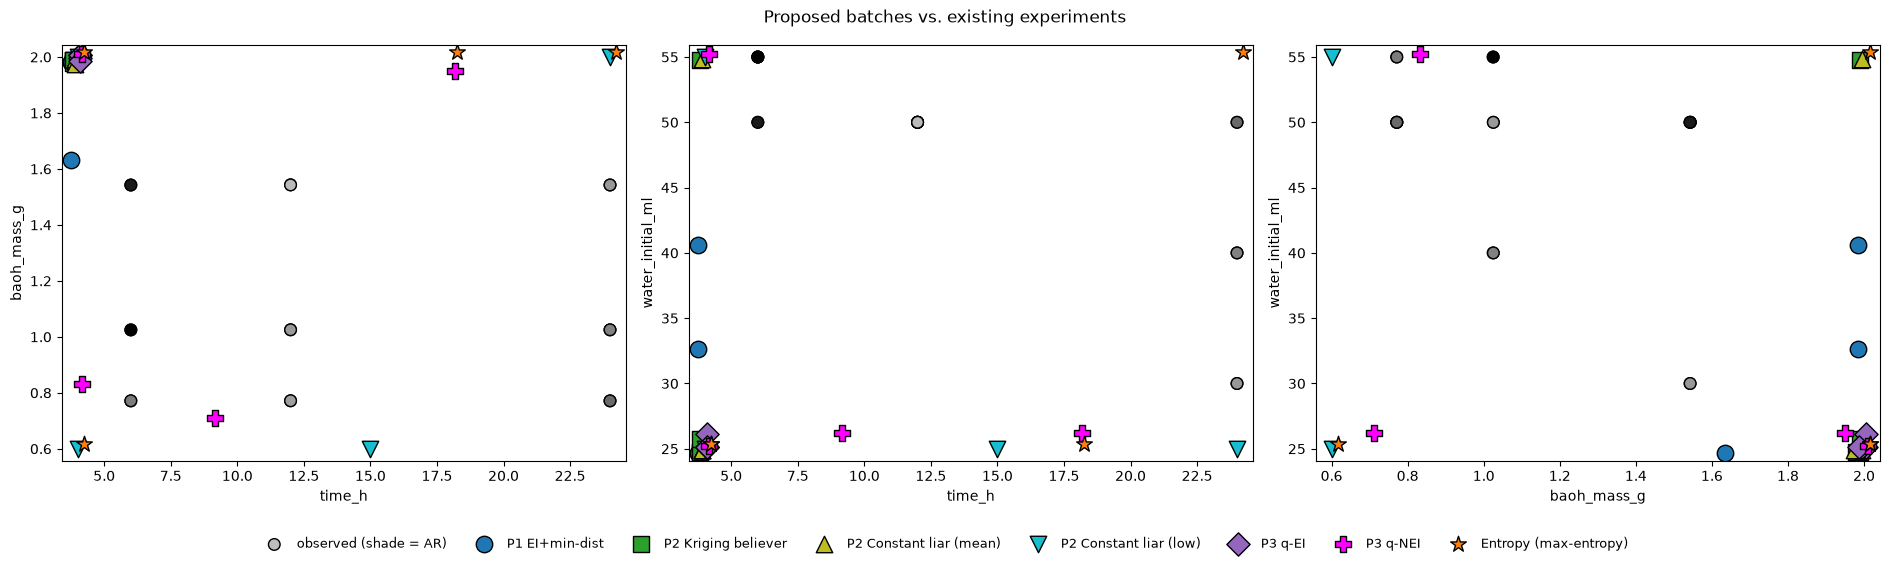

In [35]:
# ---------- Visual comparison: three 2-D projections of the 3-D space ----------
styles = {names[0]: ("tab:blue", "o"), names[1]: ("tab:green", "s"), names[2]: ("tab:olive", "^"), names[3]: ("tab:cyan", "v"),
          names[4]: ("tab:purple", "D"), names[5]: ("magenta", "P"), names[6]: ("tab:orange", "*")}
pairs = [(0, 1), (0, 2), (1, 2)]
fig, axs = plt.subplots(1, 3, figsize=(19, 5.6))
for ax, (a, b) in zip(axs, pairs):
    sc = ax.scatter(df[OPT_VARS[a]], df[OPT_VARS[b]], c=y_raw, cmap="Greys", edgecolor="k", s=70, vmin=y_raw.min(), vmax=y_raw.max(),
                    label="observed (shade = AR)", zorder=2)
    for k, (name, idx) in enumerate(BATCHES.items()):
        col, mk = styles[name]
        jit = (k - 3) * 0.004 * (hi[a] - lo[a]), (k - 3) * 0.004 * (hi[b] - lo[b])   # tiny offset so overlapping picks stay visible
        ax.scatter(pool_raw[idx, a] + jit[0], pool_raw[idx, b] + jit[1], color=col, marker=mk, s=140, edgecolor="k", label=name, zorder=3)
    ax.set_xlabel(OPT_VARS[a]); ax.set_ylabel(OPT_VARS[b]); ax.set_xlim(lo[a]-.03*(hi[a]-lo[a]), hi[a]+.03*(hi[a]-lo[a]))
    ax.set_ylim(lo[b]-.03*(hi[b]-lo[b]), hi[b]+.03*(hi[b]-lo[b]))
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=len(l_), fontsize=9, frameon=False)
fig.suptitle("Proposed batches vs. existing experiments"); plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

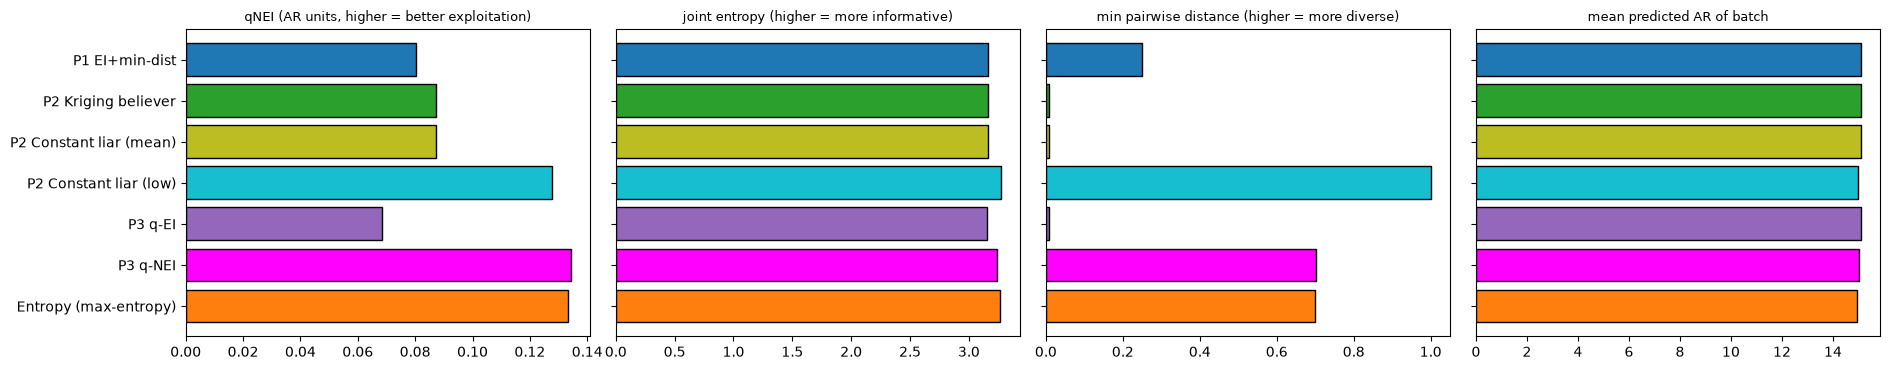

In [36]:
# ---------- Summary bar charts ----------
fig, axs = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, col, ttl in zip(axs, ["qNEI", "logdet", "min_dist", "mean_mu"],
                        ["qNEI (AR units, higher = better exploitation)", "joint entropy (higher = more informative)",
                         "min pairwise distance (higher = more diverse)", "mean predicted AR of batch"]):
    ax.barh(summary.index, summary[col], color=[styles[n][0] for n in summary.index], edgecolor="k")
    ax.set_title(ttl, fontsize=9); ax.invert_yaxis()
    if col != "qNEI": ax.set_yticklabels([])
plt.tight_layout(); plt.show()

**How to interpret (typical patterns, check against your own table):**
* **P1** is exploitative: high `mean_mu`, but diversity depends entirely on `D_MIN`, which you set by hand.
* **KB** and **CL-mean** behave similarly to each other; **CL-low** spreads the batch more (and may sacrifice predicted AR).
* **q-NEI/q-EI** should have the highest `qNEI` *by construction* (it optimizes it), a good question is *how much higher* than P1/P2. If the margin is tiny, the three prongs are practically equivalent for this problem.
* **Max-entropy** should win `logdet` and `fill` and lose on `mean_mu`: it is the exploration extreme.
* With this much replicate noise, differences of a fraction of an aspect-ratio unit in `qNEI` are **not experimentally distinguishable**.
* `qEI` (fixed incumbent) is ~0 for every batch: the incumbent is the largest *raw* measurement, which includes a lucky oven offset, and nothing in the surface can beat it. That is exactly why the noise-aware q-NEI is the version to use here.
* A batch whose recipes have different times needs **several oven runs**, see Step 11.

## Step 11: Select the experimental batch to synthesize

The choice depends on your objective **and on resources**. Rules of thumb:
* Want the best expected aspect ratio soon → a Prong-3 batch (q-NEI) or Prong 1/2 if they are close in `qNEI`.
* Model still poor (LOO-CV not better than baseline) → lean toward exploration (max-entropy or CL-low).
* A **mixed** batch is also legitimate (e.g., 3 from q-NEI + 1 from max-entropy).

**Oven runs matter for the choice.** Runs share an oven run only if they use the same time (and temperature). A batch that mixes times is really several oven runs, and each oven run brings its own unknown offset. Two practical consequences: (i) if you can only afford one oven run per round, restrict `ALLOWED_TIMES` in Step 1 to one time and re-run from Step 5; (ii) put each recipe in **at least two different oven runs** across rounds (as Round 1 did), otherwise the oven offset and the recipe effect cannot be separated.

Set `CHOSEN` below, and the cell writes a lab-ready CSV with empty result columns for Step 14. `REPLICATES` repeats each recipe (Round 1 ran every recipe twice; given the large scatter, duplicates make each result far more informative, at the cost of a smaller number of *different* recipes per round). The strategy name is saved in a `strategy` column, which Step 17 needs to compare strategies.

In [42]:
CHOSEN     = "P3 q-NEI"     # one of the keys of BATCHES (printed above)
REPLICATES = 1              # 1 = each recipe once; 2 = every recipe in two different oven runs (like Round 1)

T_CONST    = float(df["temperature_c"].iloc[0]); RINSE_CONST = float(df["water_rinse_ml"].iloc[0])
HTO_CONST  = round(float(df["hto_mass_g"].median()), 4)          # HTO is held fixed at its typical value

sel = BATCHES[CHOSEN]
out = pd.DataFrame(np.repeat(pool_raw[sel], REPLICATES, axis=0), columns=OPT_VARS)
out["replicate"] = np.tile(np.arange(REPLICATES), len(sel))

# ---- assign oven runs: runs share an oven run only if they have the SAME time and the same replicate index ----
# (a second replicate goes into a different oven run on purpose: that is what lets the GP separate oven offsets from recipe effects)
nums = df["batch_id"].str.extract(r"(\d+)")[0].astype(float)
next_b = int(nums.max()) + 1 if nums.notna().any() else 1
keys = out[["time_h", "replicate"]].drop_duplicates().sort_values(["replicate", "time_h"]).reset_index(drop=True)
keys["batch_id"] = [f"B{next_b + i}" for i in range(len(keys))]
out = out.merge(keys, on=["time_h", "replicate"], how="left").sort_values("batch_id", kind="stable").reset_index(drop=True)
out["notes"] = out["batch_id"] + "S" + (out.groupby("batch_id").cumcount() + 1).astype(str)   # same naming as Round 1 (B3S2 ...)

out.insert(0, "run_id", range(int(df.run_id.max()) + 1, int(df.run_id.max()) + 1 + len(out)))
out.insert(1, "round", int(df["round"].max()) + 1)
out.insert(2, "temperature_c", T_CONST); out.insert(4, "hto_mass_g", HTO_CONST); out["water_rinse_ml"] = RINSE_CONST
out["aspect_ratio"] = np.nan; out["purity_pct"] = np.nan          # to be filled after SEM / XRD
out["strategy"] = CHOSEN
out = out[["run_id", "round", "temperature_c", "time_h", "hto_mass_g", "baoh_mass_g", "water_initial_ml", "water_rinse_ml",
           "aspect_ratio", "purity_pct", "notes", "batch_id", "strategy"]]
out.to_csv("proposed_batch_next_round.csv", index=False)
proposals.to_csv("all_proposed_batches_comparison.csv", index=False)
display(out)

n_ovens = out["batch_id"].nunique()
print(f"These {len(out)} runs need {n_ovens} oven run(s) (runs can share an oven run only if they use the same time).")
if n_ovens > REPLICATES:
    print("If you can only do ONE oven run per round, set ALLOWED_TIMES in Step 1 to a single time and re-run from Step 5:")
    print("the strategies then compete on recipes (BaOH, water) at that time, which is also what keeps oven-run effects estimable.")
print("Saved: proposed_batch_next_round.csv (to synthesize) and all_proposed_batches_comparison.csv (for the record)")

,run_id,round,temperature_c,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,water_rinse_ml,aspect_ratio,purity_pct,notes,batch_id,strategy
0,19,2,210.0,4.0,0.1402,2.00,25.0,10.0,NaN,NaN,B7S1,B7,P3 q-NEI
1,20,2,210.0,4.0,0.1402,0.82,55.0,10.0,NaN,NaN,B7S2,B7,P3 q-NEI
2,21,2,210.0,9.0,0.1402,0.70,26.0,10.0,NaN,NaN,B8S1,B8,P3 q-NEI
3,22,2,210.0,18.0,0.1402,1.94,26.0,10.0,NaN,NaN,B9S1,B9,P3 q-NEI


These 4 runs need 3 oven run(s) (runs can share an oven run only if they use the same time).
If you can only do ONE oven run per round, set ALLOWED_TIMES in Step 1 to a single time and re-run from Step 5:
the strategies then compete on recipes (BaOH, water) at that time, which is also what keeps oven-run effects estimable.
Saved: proposed_batch_next_round.csv (to synthesize) and all_proposed_batches_comparison.csv (for the record)


## Step 12: Perform the hydrothermal synthesis (lab)

Run the recipes in `proposed_batch_next_round.csv`. Keep every other condition identical to Round 1 (temperature, HTO mass, rinse, procedure). Record deviations, unexpected observations and failed reactions in `notes`. A failed reaction is *information*: do not silently drop it (write it down and decide how to encode it, e.g. as infeasible).

## Step 13: Characterize (lab)

* **SEM** → needle length/width → aspect ratio (same measuring protocol for every sample; keep per-run values, do not average replicates in the file).
* **XRD** (± Rietveld) → phase purity (`purity_pct`).

Fill `aspect_ratio` and `purity_pct` in the CSV.

## Step 14: Update the experimental dataset

Only **measured** values enter the dataset. The helper below refuses a file that has missing results or columns that look like predictions/fantasies. It deliberately works on the *raw* table (`df_raw`) and lets Step 2 recompute `recipe_id`.

In [38]:
def append_new_results(df_old_raw, filled_csv, save_as):
    """Append the measured results of a finished round to the experimental dataset."""
    new = pd.read_csv(filled_csv)
    required = OPT_VARS + [TARGET, PURITY_COL]
    assert new[required].notna().all().all(), "Some runs have no measured aspect ratio / purity yet (or a missing parameter)."
    suspicious = [c for c in new.columns if any(t in c.lower() for t in ("fantasy", "pred", "mu_", "sd_"))]
    assert not suspicious, f"Columns that look like predictions/fantasies must not be saved as data: {suspicious}"
    merged = pd.concat([df_old_raw, new], ignore_index=True)
    merged.to_csv(save_as, index=False)
    print(f"Saved {save_as}: {len(df_old_raw)} old + {len(new)} new runs")
    return merged

# Usage after the lab work (left commented so this notebook runs end-to-end):
# df_raw_updated = append_new_results(df_raw, "proposed_batch_next_round.csv", "Experiment_Results_Rd2.csv")

## Step 15: Retrain the GP

Set `CSV_PATH = "Experiment_Results_Rd2.csv"` in Step 1 and re-run from Step 2 downward. Steps 2–5 rebuild the recipes, refit the GP on the enlarged dataset and regenerate the candidate pool; the new μ(x), σ(x) become the common starting model of the next iteration.

## Step 16: Repeat the batch-selection / experiment cycle

Re-run Steps 6–11 with the updated GP. Because all strategies start from the same data and model each round, differences between rounds' outcomes can be attributed to the **batch-selection strategy**, which is the whole point of the study.

Two practical suggestions for fair comparison across rounds:
* Each round, the proposed batch can come from **different strategies** (e.g., 2 recipes from each of two strategies, labelled in the `strategy` column), so that all strategies are tested under the same lab conditions/time.
* Keep `Q`, bounds, kernel, acquisition and `D_MIN` unchanged between rounds.

## Step 17: Evaluate optimization performance across iterations

Use **measured** outcomes only. The function below summarizes, per round and strategy: number of runs, best purity-acceptable aspect ratio, average, fraction meeting the purity requirement, and a cumulative "best so far" curve; plus the number of experiments needed to reach a target, and reproducibility (replicate std) per recipe. It needs `round` and (for rounds after the first) `strategy` columns; Round 1 is labelled `initial`.

In [39]:
def evaluate_progress(d, target_ar=None):
    d = d.copy()
    if "strategy" not in d.columns: d["strategy"] = np.nan
    d["strategy"] = d["strategy"].fillna("initial")
    d["feasible"] = d[PURITY_COL] >= PURITY_MIN
    d["AR_feasible"] = d[TARGET].where(d["feasible"])              # NaN if the sample is not pure enough
    per = (d.groupby(["round", "strategy"])
             .agg(n_runs=("run_id", "size"), mean_AR=(TARGET, "mean"),
                  best_AR_feasible=("AR_feasible", "max"), frac_feasible=("feasible", "mean")))
    cum = d.sort_values("run_id")["AR_feasible"].cummax().reset_index(drop=True)
    print("Per round and strategy:"); display(per.round(3))
    best_by_round = d.groupby("round")["AR_feasible"].max().cummax()
    print("Best purity-acceptable aspect ratio so far, by round:"); display(best_by_round.round(3).to_frame("best_so_far"))
    if target_ar is not None:
        hit = np.where(cum.values >= target_ar)[0]
        print(f"Experiments needed to reach AR >= {target_ar}: {hit[0] + 1 if len(hit) else 'not reached yet'}")
    rep_std = d.groupby("recipe_id")[TARGET].std().dropna()
    print(f"Reproducibility: median replicate std = {rep_std.median():.2f} (n recipes with replicates = {len(rep_std)})")
    return per

_ = evaluate_progress(df, target_ar=None)     # with Round 1 only this is a baseline snapshot

Per round and strategy:


C:\Users\bribi\AppData\Local\Temp\ipykernel_47512\2884635045.py:4: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  d["strategy"] = d["strategy"].fillna("initial")


,,n_runs,mean_AR,best_AR_feasible,frac_feasible
round,strategy,,,,
1,initial,18,14.93,21.821,1.0


Best purity-acceptable aspect ratio so far, by round:


,best_so_far
round,
1,21.821


Reproducibility: median replicate std = 2.75 (n recipes with replicates = 9)


## Step 18: Validate the final optimized condition

When a recipe looks best, run **several new independent replicates** and compare with the baseline recipe. With 2–4 replicates per group the statistical power is low, so report the *difference with a confidence interval* (bootstrap) and not only a p-value.

In [40]:
def compare_to_baseline(d, recipe_id_new, recipe_id_baseline, n_boot=10000, seed=0):
    """Difference in mean aspect ratio (new - baseline) with a bootstrap 95% interval, using ONLY replicates of each recipe.
    Also reports Welch's t-test. Use it on new validation runs (not on the data that selected the recipe)."""
    from scipy.stats import ttest_ind
    a = d.loc[d.recipe_id == recipe_id_new, TARGET].values
    b = d.loc[d.recipe_id == recipe_id_baseline, TARGET].values
    r = np.random.default_rng(seed)
    diffs = [r.choice(a, len(a)).mean() - r.choice(b, len(b)).mean() for _ in range(n_boot)]
    lo_ci, hi_ci = np.percentile(diffs, [2.5, 97.5])
    t = ttest_ind(a, b, equal_var=False)
    print(f"mean(new)={a.mean():.2f} (n={len(a)})  mean(base)={b.mean():.2f} (n={len(b)})  diff={a.mean()-b.mean():.2f}  "
          f"95% bootstrap CI [{lo_ci:.2f}, {hi_ci:.2f}]  Welch p={t.pvalue:.3f}")
# Usage once validation runs exist:  compare_to_baseline(df, recipe_id_new=10, recipe_id_baseline=1)

## Step 19: Drawing conclusions about the batch-selection strategies

Questions the final analysis should answer, with the caveats that apply to this problem:
1. **Does accounting for correlations (joint q-NEI) beat ranking + distance?** Compare experimentally measured best-so-far curves (Step 17), not predicted `qNEI`.
2. **Is sequential fantasy-based selection as good as joint optimization?** In a 3-variable space with q≈4, they often propose very similar batches. Check the overlap matrix in Step 10: if batches share most recipes, no experiment-level difference can emerge.
3. **Is the exploration extreme (max-entropy) worth it?** Look at the reduction in predictive uncertainty and the LOO-CV improvement it gives in the following round.

**Honest limits.** With a handful of rounds, tens of runs and replicate scatter comparable to the effect size, *real-experiment* comparisons between strategies will rarely be statistically conclusive. Two complementary tools if you need stronger evidence: (i) compare strategies *in silico* on a synthetic ground truth drawn from the fitted GP (many repetitions, free of lab cost); (ii) use the diversity/coverage/`qNEI` metrics of Step 10 across several rounds as supporting evidence.